# LSMO/STO (001): Phi scan 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

fname = "3_Phi_Scan_LSMO.ras"   # change path if needed

## 1. Parse the .ras file

In [2]:
def read_ras(path):
    header, data = {}, []
    in_data = False
    with open(path, "r", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if line.startswith("*RAS_INT_START"):
                in_data = True
                continue
            if line.startswith("*RAS_INT_END"):
                in_data = False
                continue
            if in_data:
                parts = line.split()
                if len(parts) >= 2:
                    data.append([float(p) for p in parts[:3]])
            elif line.startswith("*") and " " in line:
                key, val = line[1:].split(" ", 1)
                header[key] = val.strip().strip('"')
    cols = ["angle", "intensity", "atten"][:len(data[0])]
    return header, pd.DataFrame(data, columns=cols)

def axis_position(header, name):
    """Fixed-axis value from the header (e.g. Chi, TwoTheta, Omega)."""
    for k, v in header.items():
        if k.startswith("MEAS_COND_AXIS_NAME-") and v == name:
            return header.get("MEAS_COND_AXIS_POSITION-" + k.split("-")[1])

header, df = read_ras(fname)
print(df.shape)
df.head()

(36001, 3)


,angle,intensity,atten
0,0.00,0.0000,1.0
1,0.01,0.0000,1.0
2,0.02,1.0096,1.0
3,0.03,0.0000,1.0
4,0.04,0.0000,1.0


In [3]:
for k in ["MEAS_SCAN_AXIS_X", "MEAS_SCAN_START", "MEAS_SCAN_STOP", "MEAS_SCAN_STEP",
          "MEAS_SCAN_SPEED", "MEAS_SCAN_SPEED_UNIT", "MEAS_DATA_COUNT"]:
    print(f"{k:24s}: {header.get(k)}")
for ax_name in ["TwoTheta", "Omega", "Chi"]:
    print(f"fixed {ax_name:9s}: {axis_position(header, ax_name)} deg")

MEAS_SCAN_AXIS_X        : Phi
MEAS_SCAN_START         : 0.000
MEAS_SCAN_STOP          : 360.000
MEAS_SCAN_STEP          : 0.010
MEAS_SCAN_SPEED         : 10.000
MEAS_SCAN_SPEED_UNIT    : deg/min
MEAS_DATA_COUNT         : 36001
fixed TwoTheta : 39.7825 deg
fixed Omega    : 19.8912 deg
fixed Chi      : 54.736 deg


## 2. Plot

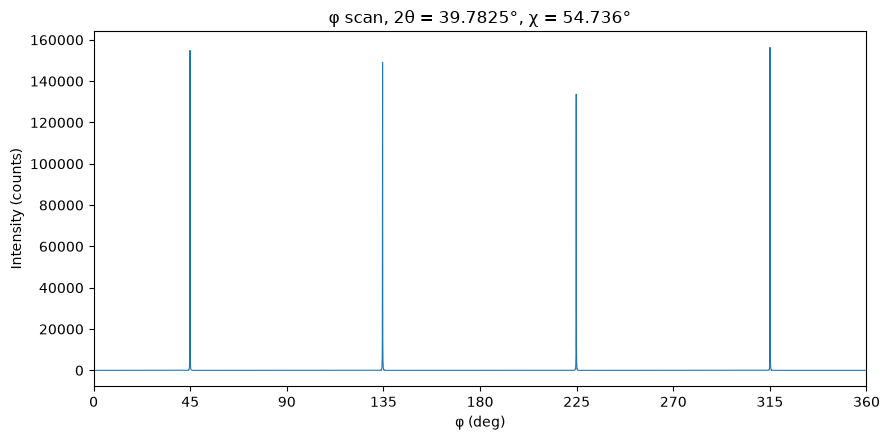

In [4]:
phi, I = df["angle"].values, df["intensity"].values

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(phi, I, lw=0.8, color="C0")
ax.set_xlabel("φ (deg)")
ax.set_ylabel("Intensity (counts)")
ax.set_title(f"φ scan, 2θ = {axis_position(header,'TwoTheta')}°, χ = {axis_position(header,'Chi')}°")
ax.set_xlim(0, 360)
ax.set_xticks(np.arange(0, 361, 45))
plt.tight_layout()
plt.savefig("lsmo_phi_scan.png", dpi=300)
plt.show()

## 3. Peak positions and spacing 
### For a cubic/pseudo-cubic (001) film, a 4-fold pattern with peaks spaced by 90° indicates cube-on-cube epitaxy with no in-plane rotated domains.

In [6]:
# light smoothing (1° window = 100 points) to suppress counting noise
ys = pd.Series(I).rolling(21, center=True, min_periods=1).mean().values
idx, props = find_peaks(ys, prominence=0.1*ys.max(), distance=int(30/0.01))

rows = []
for i in idx:
    sl = slice(max(i-100, 0), i+101)           # ±1° window
    w = ys[sl] - ys[sl].min()
    centroid = np.sum(phi[sl]*w) / np.sum(w)    # intensity-weighted centre
    rows.append({"phi (deg)": round(centroid, 3), "counts": round(I[i])})
peaks = pd.DataFrame(rows)
peaks["spacing to previous (deg)"] = peaks["phi (deg)"].diff().round(3)
peaks

,phi (deg),counts,spacing to previous (deg)
0,44.890,138721,NaN
1,134.584,135306,89.694
2,224.797,131204,90.213
3,315.072,156309,90.275


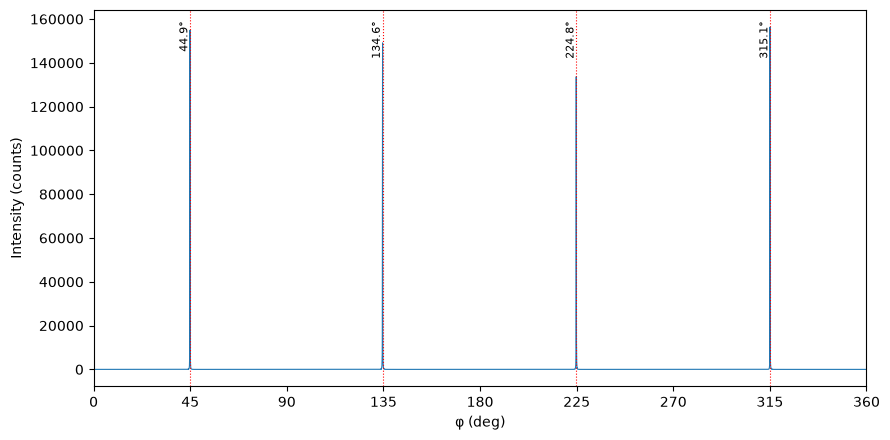

phi =   44.89°   FWHM ≈ 0.13°
phi =  134.58°   FWHM ≈ 0.13°
phi =  224.80°   FWHM ≈ 0.13°
phi =  315.07°   FWHM ≈ 0.12°


In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(phi, I, lw=0.8)
for p in peaks["phi (deg)"]:
    ax.axvline(p, color="r", ls=":", lw=0.8)
    ax.text(p, ax.get_ylim()[1]*0.97, f"{p:.1f}°", rotation=90, ha="right", va="top", fontsize=8)
ax.set_xlabel("φ (deg)"); ax.set_ylabel("Intensity (counts)"); ax.set_xlim(0, 360)
ax.set_xticks(np.arange(0, 361, 45))
plt.tight_layout(); plt.show()

# FWHM of the first peak
def fwhm(center, half=5):
    m = (phi > center-half) & (phi < center+half)
    x_, y_ = phi[m], pd.Series(I[m]).rolling(11, center=True, min_periods=1).mean().values
    above = x_[y_ >= y_.max()/2]
    return above.max() - above.min()
for p in peaks["phi (deg)"]:
    print(f"phi = {p:7.2f}°   FWHM ≈ {fwhm(p):.2f}°")